# 14 — Laporan hasil penelitian VAEP-Track

Notebook ini menjawab: **data mana yang diuji, berapa hasil setiap model, dan kesalahan apa yang masih terjadi?**
Setiap bagian berisi penjelasan, kode, dan keluaran. Jalankan **Run All** dengan kernel **Python (VAEP-Track)**.
Notebook hanya menghitung ulang laporan dari prediksi yang sudah disimpan. Tidak melatih ulang model atau mengubah anotasi.

**Label 1 = gegenpressing menurut anotasi; label 0 = bukan gegenpressing menurut anotasi.**
Hasil klasifikasi ini mengukur kesesuaian model dengan anotasi, belum merupakan nilai VAEP atau bukti bahwa sebuah taktik menyebabkan kemenangan.

Urutan membaca: sumber hasil → pembagian data → pemeriksaan → metrik → grafik → kesalahan → interpretasi.

## 1. Memilih hasil pelatihan lengkap

Kode mencari direktori proyek dari lokasi notebook, lalu memilih run terbaru yang berstatus `final_training_complete`.
Nama run dicetak supaya sumber setiap angka dapat dilacak. Untuk mengulang laporan dari run tertentu, isi `RUN_NAME` dengan nama direktori tersebut.
Folder laporan terpisah dari hasil pelatihan asli. Seed dicatat untuk reproduksibilitas; laporan ini tidak melakukan sampling atau pelatihan.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_fscore_support, roc_curve, precision_recall_curve,
)

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'src').is_dir() and (p / 'artifacts').is_dir()
)
RUN_NAME = os.environ.get('VAEP_REPORT_RUN', '')  # Isi untuk memilih satu run tertentu.
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

completed = []
for path in (PROJECT_ROOT / 'artifacts').glob('final_training_*'):
    manifest_path = path / 'run_manifest.json'
    if manifest_path.is_file():
        manifest = read_json(manifest_path)
        if manifest.get('status') == 'final_training_complete':
            completed.append((manifest.get('created_at_utc', ''), path))
if RUN_NAME:
    if Path(RUN_NAME).name != RUN_NAME:
        raise ValueError('RUN_NAME harus berupa nama folder run, bukan path.')
    RUN_DIR = PROJECT_ROOT / 'artifacts' / RUN_NAME
else:
    if not completed:
        raise RuntimeError('Belum ada pelatihan lengkap. Jalankan pemeriksaan kesiapan terlebih dahulu.')
    RUN_DIR = max(completed, key=lambda item: item[0])[1]
run_info = read_json(RUN_DIR / 'run_manifest.json')
assert run_info['status'] == 'final_training_complete'
REPORT_DIR = PROJECT_ROOT / 'artifacts' / 'laporan_hasil' / RUN_DIR.name
REPORT_DIR.mkdir(parents=True, exist_ok=True)
SEED = int(run_info['random_state'])
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Run sumber :', RUN_DIR.name)
print('Status     :', run_info['status'])
print('Seed       :', SEED)
print('Laporan    :', REPORT_DIR)

Run sumber : final_training_20261027T152829Z
Status     : final_training_complete
Seed       : 42
Laporan    : c:\VAEP-Track\artifacts\laporan_hasil\final_training_20261027T152829Z


## 2. Membaca bukti yang disimpan saat pelatihan

`frozen_annotations` dan `frozen_model_manifest` adalah salinan anotasi serta pembagian data saat run dilakukan.
`combined_predictions` menyimpan probabilitas, label aktual, dan prediksi untuk setiap model dan episode.
Satu episode muncul sekali untuk masing-masing model: jumlah baris prediksi **bukan** jumlah episode unik.

In [2]:
annotations = pd.read_csv(RUN_DIR / 'frozen_annotations.csv')
episodes = pd.read_csv(RUN_DIR / 'frozen_model_manifest.csv')
predictions = pd.read_csv(RUN_DIR / 'evaluation' / 'combined_predictions.csv')
saved_metrics = pd.read_csv(RUN_DIR / 'evaluation' / 'split_metrics.csv')
history = pd.read_csv(RUN_DIR / 'temporal_gnn' / 'training_history.csv')
gnn_info = read_json(RUN_DIR / 'temporal_gnn' / 'metadata.json')
training_environment = read_json(RUN_DIR / 'environment.json')
review_queue = pd.read_csv(RUN_DIR / 'annotation_review_queue.csv')
SPLITS = ['train', 'validation', 'test']
MODEL_NAMES = {
    'logistic_regression': 'Logistic Regression',
    'xgboost': 'XGBoost',
    'temporal_gnn': 'Temporal GNN',
    'majority_baseline': 'Selalu kelas mayoritas latih',
}
MODELS = ['logistic_regression', 'xgboost', 'temporal_gnn']
assert set(predictions['model']) == set(MODELS)
print(f'Episode unik: {episodes.candidate_id.nunique():,}')
print(f'Baris prediksi: {len(predictions):,} = episode × {len(MODELS)} model')
display(predictions.head(5))
print('Versi lingkungan pelatihan (bukan perkiraan):')
display(pd.json_normalize(training_environment).T.rename(columns={0: 'nilai'}))

Episode unik: 1,873
Baris prediksi: 5,619 = episode × 3 model


,model,split,candidate_id,match_id,y_true,probability,threshold,y_pred
0,logistic_regression,train,J03WMX_P1_F10587,J03WMX,1,0.380223,0.291708,1
1,logistic_regression,train,J03WMX_P1_F11071,J03WMX,1,0.632223,0.291708,1
2,logistic_regression,train,J03WMX_P1_F11238,J03WMX,0,0.154862,0.291708,0
3,logistic_regression,train,J03WMX_P1_F12051,J03WMX,1,0.692532,0.291708,1
4,logistic_regression,train,J03WMX_P1_F12133,J03WMX,1,0.573381,0.291708,1


Versi lingkungan pelatihan (bukan perkiraan):


,nilai
python,3.13.3
platform,Windows-11-10.0.26300-SP0
torch,2.12.0+cu130
torch_geometric,2.8.0.post1
cuda_available,True
cuda_device,NVIDIA GeForce RTX 3050 6GB Laptop GPU
scikit_learn,1.9.1
xgboost,3.4.1
git_commit,bec29fc185fd2ba40d29c77e7029370812f288a3
git_dirty,True


## 3. Memastikan laporan membandingkan data yang sama

Pemeriksaan berikut memastikan setiap model memakai episode, label, dan pembagian pertandingan yang sama;
serta keputusan prediksi sesuai threshold yang sudah disimpan. Hash memeriksa perubahan pada artefak run yang tercatat.
Pemeriksaan ini menguji konsistensi berkas, **tidak membuktikan setiap anotasi taktis sudah benar**.
Jika pemeriksaan gagal, hentikan interpretasi hasil dan periksa sumber perbedaannya.

In [3]:
checks = {}
checks['ID episode unik'] = episodes.candidate_id.is_unique
checks['ID anotasi unik'] = annotations.candidate_id.is_unique
checks['Pasangan model dan episode unik'] = not predictions.duplicated(['model', 'candidate_id']).any()
checks['Satu pertandingan hanya dalam satu split'] = episodes.groupby('match_id')['split'].nunique().eq(1).all()
checks['Semua split tersedia'] = set(episodes['split']) == set(SPLITS)
checks['Label anotasi biner'] = annotations.is_gegenpressing.isin([0, 1]).all()
checks['Probabilitas valid'] = predictions.probability.between(0, 1).all()
checks['Keputusan sesuai threshold tersimpan'] = (
    predictions.y_pred == (predictions.probability >= predictions.threshold).astype(int)
).all()
checks['Satu threshold tersimpan per model'] = predictions.groupby('model').threshold.nunique().eq(1).all()
expected = episodes.set_index('candidate_id').sort_index()
ann_labels = annotations.set_index('candidate_id').is_gegenpressing
checks['Label manifest sama dengan anotasi beku'] = (
    expected.gegenpressing_label == ann_labels.reindex(expected.index)
).all()
for model in MODELS:
    actual = predictions[predictions.model == model].set_index('candidate_id').sort_index()
    checks[f'{model}: episode lengkap'] = actual.index.equals(expected.index)
    aligned = actual.reindex(expected.index)
    checks[f'{model}: label/split/pertandingan sama'] = bool(
        (aligned.y_true == expected.gegenpressing_label).all()
        and (aligned['split'] == expected['split']).all()
        and (aligned.match_id == expected.match_id).all()
    )
# Hanya berkas dalam run: data/processed dapat berubah setelah pelatihan.
hash_rows = []
for relative, digest in run_info.get('artifact_sha256', {}).items():
    local = RUN_DIR / Path(relative.replace('\\\\', '/'))
    if local.is_file() and local.resolve().is_relative_to(RUN_DIR.resolve()):
        with local.open('rb') as stream:
            actual_digest = hashlib.file_digest(stream, 'sha256').hexdigest()
        hash_rows.append({'file': relative, 'cocok': actual_digest == digest})
checks['Ada hash artefak run yang diperiksa'] = bool(hash_rows)
checks['Hash artefak run cocok'] = all(row['cocok'] for row in hash_rows)
check_table = pd.DataFrame({'pemeriksaan': checks.keys(), 'lulus': checks.values()})
display(check_table)
assert all(checks.values()), 'Ada pemeriksaan gagal; jangan lanjut menafsirkan hasil.'
display(pd.DataFrame(hash_rows))

,pemeriksaan,lulus
0,ID episode unik,True
1,ID anotasi unik,True
2,Pasangan model dan episode unik,True
3,Satu pertandingan hanya dalam satu split,True
4,Semua split tersedia,True
5,Label anotasi biner,True
6,Probabilitas valid,True
7,Keputusan sesuai threshold tersimpan,True
8,Satu threshold tersimpan per model,True
9,Label manifest sama dengan anotasi beku,True


,file,cocok
0,frozen_annotations.csv,True
1,annotation_audit_summary.csv,True
2,annotation_review_queue.csv,True
3,baseline\logistic_regression.joblib,True
4,baseline\xgboost.joblib,True
5,temporal_gnn\temporal_gnn.pt,True
6,evaluation\split_metrics.csv,True
7,evaluation\match_metrics.csv,True


## 4. Apa itu data latih, validasi, dan uji?

- **Latih (train):** digunakan untuk mempelajari bobot/pola model.
- **Validasi (validation):** digunakan untuk pemilihan model/checkpoint dan threshold sesuai pipeline.
- **Uji (test):** digunakan untuk mengukur hasil pada pertandingan yang ditahan dari proses pelatihan dan pemilihan tersebut.

Pembagian dilakukan berdasarkan **pertandingan**, bukan mengacak episode dari pertandingan yang sama ke semua split.
Jangan menjumlahkan hasil tiga model seolah-olah berasal dari tiga dataset berbeda.

,episode,positif,negatif,persen_positif,jumlah_pertandingan,pertandingan
split,,,,,,
train,1355,1162,193,85.76,5,"J03WMX, J03WN1, J03WOH, J03WOY, J03WR9"
validation,195,163,32,83.59,1,J03WQQ
test,323,256,67,79.26,1,J03WPY


**Jadi, 1,873 episode adalah keseluruhan data. Angka hasil uji dihitung dari 323 episode pada 1 pertandingan uji.**

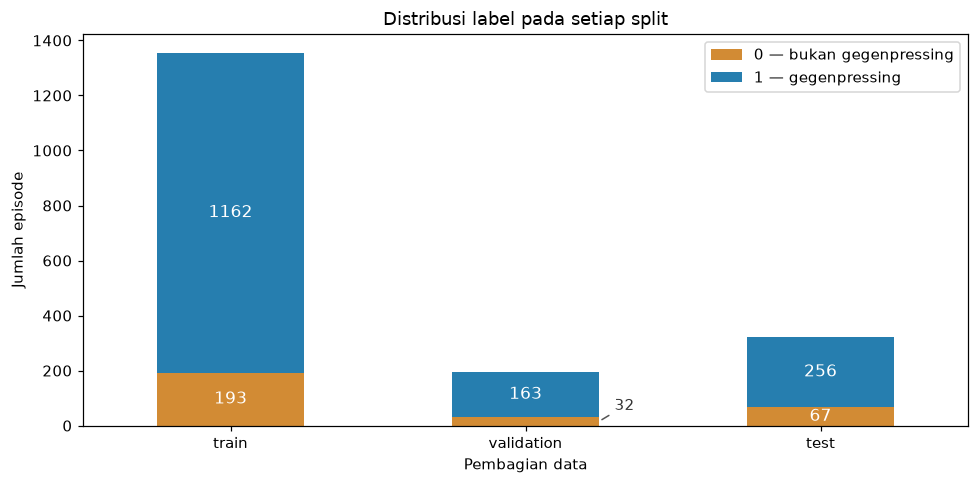

In [4]:
split_table = episodes.groupby('split').agg(
    episode=('candidate_id', 'size'),
    positif=('gegenpressing_label', 'sum'),
    jumlah_pertandingan=('match_id', 'nunique'),
    pertandingan=('match_id', lambda x: ', '.join(sorted(x.unique()))),
).reindex(SPLITS)
split_table['positif'] = split_table['positif'].astype(int)
split_table['negatif'] = split_table.episode - split_table.positif
split_table['persen_positif'] = 100 * split_table.positif / split_table.episode
display(split_table[['episode', 'positif', 'negatif', 'persen_positif', 'jumlah_pertandingan', 'pertandingan']].round(2))
assert split_table.episode.sum() == len(episodes)
test_n = int(split_table.loc['test', 'episode'])
test_match_n = int(split_table.loc['test', 'jumlah_pertandingan'])
display(Markdown(
    f'**Jadi, {len(episodes):,} episode adalah keseluruhan data. '
    f'Angka hasil uji dihitung dari {test_n} episode pada {test_match_n} pertandingan uji.**'
))

def save_figure(fig, name):
    fig.savefig(REPORT_DIR / f'{name}.png', dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_counts = split_table[['negatif', 'positif']].rename(columns={
    'negatif': '0 — bukan gegenpressing', 'positif': '1 — gegenpressing'
})
plot_counts.plot.bar(stacked=True, ax=ax, color=['#d28b34', '#267eaf'], rot=0)
for container in ax.containers:
    labels = [str(int(value)) if value >= 60 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', color='white', fontsize=11)
    for rect in container:
        if 0 < rect.get_height() < 60:
            ax.annotate(str(int(rect.get_height())),
                        xy=(rect.get_x() + rect.get_width(), rect.get_y() + rect.get_height() / 2),
                        xytext=(10, 10), textcoords='offset points', ha='left', va='center',
                        arrowprops={'arrowstyle': '-', 'color': '#555555'}, color='#333333')
ax.set(xlabel='Pembagian data', ylabel='Jumlah episode', title='Distribusi label pada setiap split')
ax.legend(loc='upper right')
fig.tight_layout()
save_figure(fig, '01_distribusi_data')

## 5. Menghitung metrik dari prediksi, bukan mengetik hasil manual

| Ukuran | Makna |
|---|---|
| Accuracy | Proporsi semua prediksi yang benar. Dapat terlihat tinggi jika satu kelas dominan. |
| Precision kelas 1 | Dari prediksi gegenpressing, berapa bagian yang benar menurut anotasi? |
| Recall kelas 1 | Dari semua gegenpressing menurut anotasi, berapa bagian yang ditemukan? |
| F1 kelas 1 | Rata-rata harmonik precision dan recall kelas 1. Ini bukan accuracy. |
| Recall kelas 0 | Dari semua bukan gegenpressing, berapa bagian dikenali dengan benar? |
| Macro F1 | Rata-rata F1 kelas 0 dan 1, kedua kelas diberi bobot sama. |
| Balanced accuracy | Rata-rata recall kelas 0 dan 1. |
| ROC-AUC | Kemampuan skor mengurutkan kelas positif di atas kelas negatif lintas threshold. |
| AP | Average Precision: ringkasan precision–recall berdasarkan skor, tanpa satu threshold tertentu. |

Berkas lama menamai kolom AP sebagai `pr_auc`, tetapi perhitungannya menggunakan `average_precision_score`.
Di laporan ini istilahnya **AP**, bukan luas trapezoidal kurva PR. Semua metrik dasar bernilai 0–1.
Threshold model diambil dari hasil pemilihan pada validasi; notebook ini **tidak mencari threshold terbaik pada test**.

In [5]:
def calculate_metrics(frame):
    y = frame.y_true.to_numpy(dtype=int)
    pred = frame.y_pred.to_numpy(dtype=int)
    prob = frame.probability.to_numpy(dtype=float)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        'samples': len(y), 'accuracy': accuracy_score(y, pred),
        'precision_1': precision_score(y, pred, zero_division=0),
        'recall_1': recall_score(y, pred, zero_division=0),
        'f1_1': f1_score(y, pred, zero_division=0),
        'recall_0': recall_score(y, pred, pos_label=0, zero_division=0),
        'macro_f1': f1_score(y, pred, average='macro', labels=[0, 1], zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(y, pred),
        'roc_auc': roc_auc_score(y, prob),
        'ap': average_precision_score(y, prob),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

rows = []
for (model, split), group in predictions.groupby(['model', 'split']):
    rows.append({'model': model, 'split': split, **calculate_metrics(group)})
recalculated = pd.DataFrame(rows)
# Hasil hitung ulang harus cocok dengan metrik run asli.
verified = recalculated.merge(saved_metrics, on=['model', 'split'], suffixes=('_new', '_saved'), validate='one_to_one')
for new, old in [('accuracy_new', 'accuracy_saved'), ('precision_1', 'precision'),
                 ('recall_1', 'recall'), ('f1_1', 'f1'), ('roc_auc_new', 'roc_auc_saved'), ('ap', 'pr_auc')]:
    np.testing.assert_allclose(verified[new], verified[old], atol=1e-10, rtol=1e-10)
display(recalculated[['model', 'split', 'samples', 'accuracy', 'f1_1', 'macro_f1', 'balanced_accuracy', 'roc_auc', 'ap']].round(4))
print('LULUS: metrik hitung ulang cocok dengan hasil evaluasi tersimpan untuk semua model dan split.')
display(predictions.groupby('model').threshold.first().rename('threshold_dari_validasi').to_frame())

,model,split,samples,accuracy,f1_1,macro_f1,balanced_accuracy,roc_auc,ap
0,logistic_regression,test,323,0.7771,0.8657,0.6056,0.5949,0.7231,0.9077
1,logistic_regression,train,1355,0.8576,0.9193,0.6553,0.6339,0.7442,0.9379
2,logistic_regression,validation,195,0.8564,0.9200,0.6100,0.5876,0.7040,0.9129
3,temporal_gnn,test,323,0.8669,0.9187,0.7756,0.7507,0.8764,0.9533
4,temporal_gnn,train,1355,0.8841,0.9344,0.7180,0.6862,0.8445,0.9629
5,temporal_gnn,validation,195,0.8872,0.9341,0.7706,0.7442,0.9032,0.9794
6,xgboost,test,323,0.8080,0.8860,0.6391,0.6200,0.7342,0.9061
7,xgboost,train,1355,0.9218,0.9554,0.8190,0.7837,0.9414,0.9895
8,xgboost,validation,195,0.8564,0.9195,0.6264,0.6002,0.7034,0.9147


LULUS: metrik hitung ulang cocok dengan hasil evaluasi tersimpan untuk semua model dan split.


,threshold_dari_validasi
model,
logistic_regression,0.291708
temporal_gnn,0.600231
xgboost,0.312450


## 6. Perbandingan pada data uji dan pembanding sederhana

Karena label 1 lebih banyak, tambahkan pembanding yang **selalu memilih kelas mayoritas data latih**.
Kelas mayoritas dan skor konstan pembanding ditentukan dari data latih, bukan dipilih berdasarkan test.
Pembanding ini tidak memiliki kemampuan membedakan episode, tetapi akurasinya bisa cukup tinggi.
Gunakan accuracy bersama macro F1, balanced accuracy, dan recall kelas 0 untuk membaca hasil dengan adil.

Pembanding selalu memprediksi label 1, ditentukan dari TRAIN.
Tabel berikut dalam persen (%). ROC-AUC dan AP dilaporkan terpisah pada skala 0–1.


,accuracy,precision_1,recall_1,f1_1,recall_0,macro_f1,balanced_accuracy
model,,,,,,,
Logistic Regression,77.71,82.86,90.62,86.57,28.36,60.56,59.49
XGBoost,80.80,83.68,94.14,88.60,29.85,63.91,62.00
Temporal GNN,86.69,89.01,94.92,91.87,55.22,77.56,75.07
Selalu kelas mayoritas latih,79.26,79.26,100.00,88.43,0.00,44.21,50.00


,roc_auc,ap
model,,
Logistic Regression,0.7231,0.9077
XGBoost,0.7342,0.9061
Temporal GNN,0.8764,0.9533
Selalu kelas mayoritas latih,0.5000,0.7926


Temporal GNN: **accuracy 86.69%**, **F1 kelas 1 91.87%**. Selisih accuracy terhadap XGBoost: **5.88 poin persentase**. Pembanding mayoritas mencapai accuracy **79.26%** tetapi balanced accuracy hanya **50.00%**. Perbandingan ini deskriptif pada split ini; belum merupakan uji signifikansi.

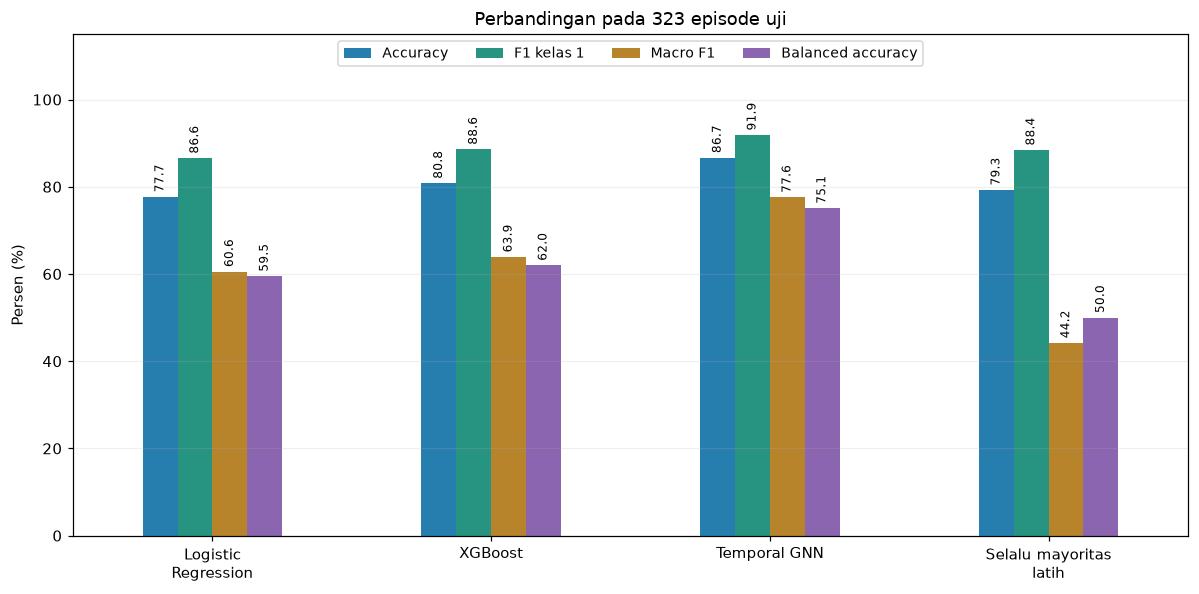

In [6]:
train_labels = episodes.loc[episodes['split'].eq('train'), 'gegenpressing_label'].astype(int)
majority_label = int(train_labels.mode().iloc[0])
majority = predictions.loc[
    predictions.model.eq('temporal_gnn') & predictions['split'].eq('test')
].copy()
majority['model'] = 'majority_baseline'
majority['probability'] = float(train_labels.mean())
majority['y_pred'] = majority_label
majority['threshold'] = np.nan  # Tidak ada threshold yang dituning untuk aturan mayoritas.
test_predictions = pd.concat([predictions[predictions['split'].eq('test')], majority], ignore_index=True)
test_metrics = pd.DataFrame([
    {'model': model, **calculate_metrics(group)}
    for model, group in test_predictions.groupby('model')
]).set_index('model').reindex([*MODELS, 'majority_baseline'])
percent_columns = ['accuracy', 'precision_1', 'recall_1', 'f1_1', 'recall_0', 'macro_f1', 'balanced_accuracy']
percent_table = (test_metrics[percent_columns] * 100).rename(index=MODEL_NAMES)
print(f'Pembanding selalu memprediksi label {majority_label}, ditentukan dari TRAIN.')
print('Tabel berikut dalam persen (%). ROC-AUC dan AP dilaporkan terpisah pada skala 0–1.')
display(percent_table.round(2))
display(test_metrics[['roc_auc', 'ap']].rename(index=MODEL_NAMES).round(4))
gnn = test_metrics.loc['temporal_gnn']
xgb = test_metrics.loc['xgboost']
majority_score = test_metrics.loc['majority_baseline']
display(Markdown(
    f"Temporal GNN: **accuracy {gnn.accuracy:.2%}**, **F1 kelas 1 {gnn.f1_1:.2%}**. "
    f"Selisih accuracy terhadap XGBoost: **{100 * (gnn.accuracy - xgb.accuracy):.2f} poin persentase**. "
    f"Pembanding mayoritas mencapai accuracy **{majority_score.accuracy:.2%}** "
    f"tetapi balanced accuracy hanya **{majority_score.balanced_accuracy:.2%}**. "
    'Perbandingan ini deskriptif pada split ini; belum merupakan uji signifikansi.'
))
fig, ax = plt.subplots(figsize=(11, 5.5))
chart = percent_table[['accuracy', 'f1_1', 'macro_f1', 'balanced_accuracy']].rename(columns={
    'accuracy': 'Accuracy', 'f1_1': 'F1 kelas 1', 'macro_f1': 'Macro F1', 'balanced_accuracy': 'Balanced accuracy'
})
chart.plot.bar(ax=ax, rot=0, color=['#267eaf', '#279381', '#b7832b', '#8b65af'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', fontsize=8, rotation=90, padding=3)
ax.set(ylim=(0, 115), ylabel='Persen (%)', xlabel='', title=f'Perbandingan pada {test_n} episode uji')
ax.set_xticklabels(['Logistic\nRegression', 'XGBoost', 'Temporal GNN', 'Selalu mayoritas\nlatih'])
ax.legend(loc='upper center', ncol=4, fontsize=9)
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
save_figure(fig, '02_perbandingan_metrik_uji')

## 7. Membaca confusion matrix dan hasil per kelas

**Baris = label aktual dari anotasi. Kolom = prediksi model.**
- Kiri atas (TN): bukan gegenpressing, diprediksi bukan gegenpressing.
- Kanan atas (FP): bukan gegenpressing, tetapi diprediksi gegenpressing.
- Kiri bawah (FN): gegenpressing, tetapi tidak terdeteksi model.
- Kanan bawah (TP): gegenpressing yang terdeteksi dengan benar.

Persentase dalam gambar dihitung **per baris aktual**, sehingga terlihat berapa bagian setiap kelas yang dikenali.
Support pada tabel adalah jumlah episode aktual dalam kelas tersebut.

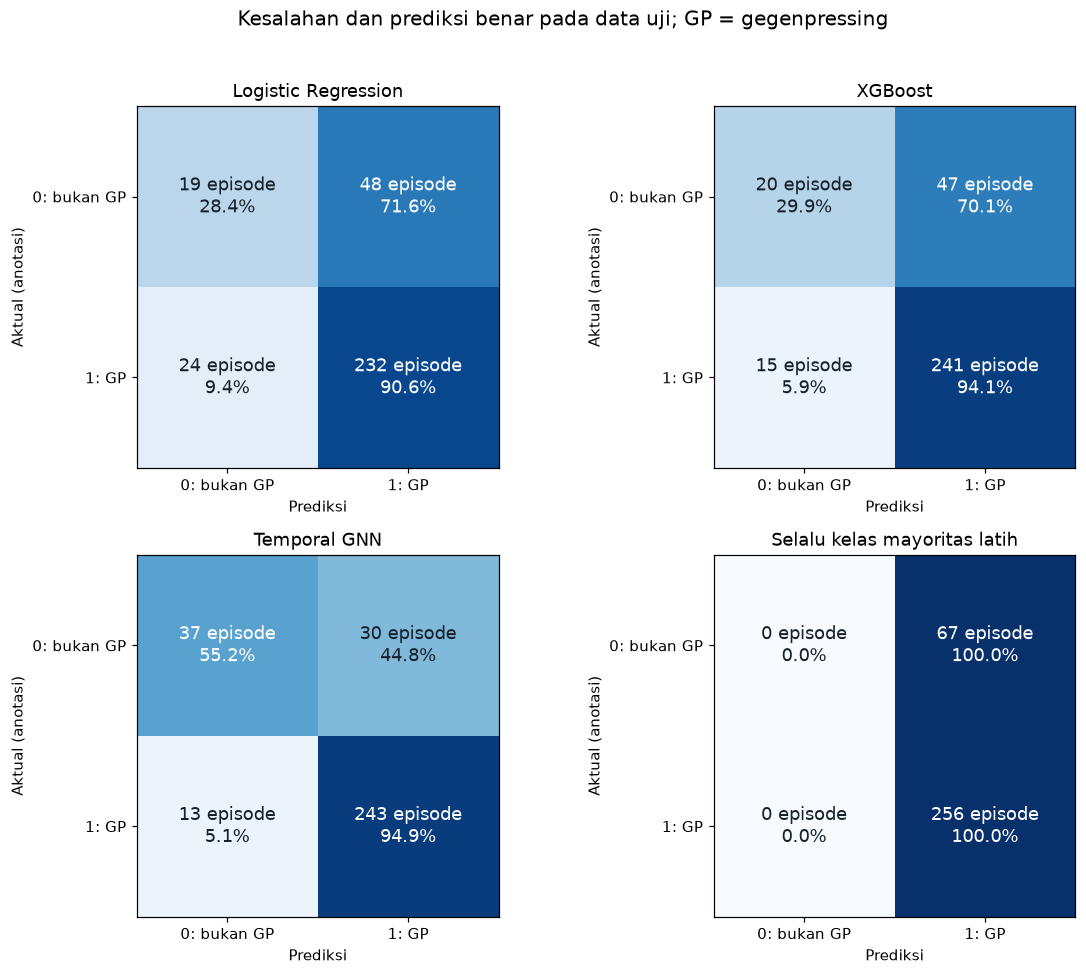

,model,kelas,precision,recall,f1,support
0,logistic_regression,0,0.4419,0.2836,0.3455,67
1,logistic_regression,1,0.8286,0.9062,0.8657,256
2,xgboost,0,0.5714,0.2985,0.3922,67
3,xgboost,1,0.8368,0.9414,0.8860,256
4,temporal_gnn,0,0.7400,0.5522,0.6325,67
5,temporal_gnn,1,0.8901,0.9492,0.9187,256
6,majority_baseline,0,0.0000,0.0000,0.0000,67
7,majority_baseline,1,0.7926,1.0000,0.8843,256


GNN mengenali **243 dari 256** episode gegenpressing (recall kelas 1 **94.92%**), tetapi hanya **37 dari 67** episode bukan gegenpressing (recall kelas 0 **55.22%**). Ada **30 FP** dan **13 FN**. Inilah alasan accuracy atau F1 kelas 1 saja belum cukup.

In [7]:
class_rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, model in zip(axes.ravel(), [*MODELS, 'majority_baseline']):
    data = test_predictions[test_predictions.model.eq(model)]
    cm = confusion_matrix(data.y_true, data.y_pred, labels=[0, 1])
    row_percent = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(row_percent, vmin=0, vmax=100, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i,j]} episode\n{row_percent[i,j]:.1f}%', ha='center', va='center',
                    color='white' if row_percent[i,j] > 55 else '#17212b', fontsize=12)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['0: bukan GP', '1: GP'],
           yticklabels=['0: bukan GP', '1: GP'], xlabel='Prediksi', ylabel='Aktual (anotasi)',
           title=MODEL_NAMES[model])
    precision, recall, f1, support = precision_recall_fscore_support(
        data.y_true, data.y_pred, labels=[0, 1], zero_division=0
    )
    for label in [0, 1]:
        class_rows.append({'model': model, 'kelas': label, 'precision': precision[label],
                           'recall': recall[label], 'f1': f1[label], 'support': int(support[label])})
fig.suptitle('Kesalahan dan prediksi benar pada data uji; GP = gegenpressing', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .96))
save_figure(fig, '03_confusion_matrix')
class_metrics = pd.DataFrame(class_rows)
display(class_metrics.round(4))
display(Markdown(
    f"GNN mengenali **{int(gnn.tp)} dari {int(gnn.tp + gnn.fn)}** episode gegenpressing "
    f"(recall kelas 1 **{gnn.recall_1:.2%}**), tetapi hanya **{int(gnn.tn)} dari "
    f"{int(gnn.tn + gnn.fp)}** episode bukan gegenpressing "
    f"(recall kelas 0 **{gnn.recall_0:.2%}**). Ada **{int(gnn.fp)} FP** dan **{int(gnn.fn)} FN**. "
    'Inilah alasan accuracy atau F1 kelas 1 saja belum cukup.'
))

## 8. ROC dan precision–recall: kualitas skor pada berbagai threshold

ROC membandingkan true positive rate (recall) dengan false positive rate.
Kurva precision–recall membantu melihat pertukaran ketepatan prediksi positif dan jumlah positif yang ditemukan.
Garis horizontal pada grafik PR adalah prevalensi positif test sebagai acuan pembanding skor tanpa kemampuan pemeringkatan.
Kurva ini bersifat diagnostik: jangan memilih threshold baru dari grafik test lalu menyebutnya evaluasi independen.
Probabilitas model juga belum diuji kalibrasinya, sehingga skor 0,90 tidak otomatis berarti kepastian 90%.

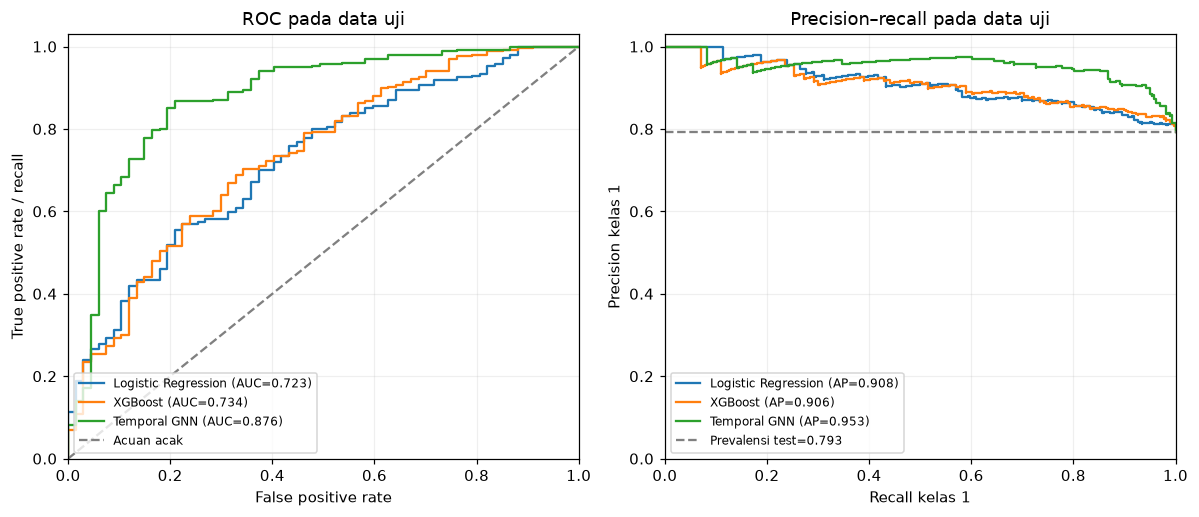

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for model in MODELS:
    data = test_predictions[test_predictions.model.eq(model)]
    fpr, tpr, _ = roc_curve(data.y_true, data.probability)
    precision, recall, _ = precision_recall_curve(data.y_true, data.probability)
    axes[0].plot(fpr, tpr, label=f'{MODEL_NAMES[model]} (AUC={test_metrics.loc[model, "roc_auc"]:.3f})')
    axes[1].step(recall, precision, where='post', label=f'{MODEL_NAMES[model]} (AP={test_metrics.loc[model, "ap"]:.3f})')
prevalence = float(majority.y_true.mean())
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Acuan acak')
axes[1].axhline(prevalence, ls='--', color='gray', label=f'Prevalensi test={prevalence:.3f}')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate / recall', title='ROC pada data uji')
axes[1].set(xlabel='Recall kelas 1', ylabel='Precision kelas 1', title='Precision–recall pada data uji')
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.03)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8, loc='lower left')
fig.tight_layout()
save_figure(fig, '04_roc_precision_recall')

## 9. Riwayat belajar Temporal GNN

Loss adalah nilai kesalahan yang diminimalkan selama pelatihan; **bukan persentase accuracy**.
Checkpoint yang dipakai adalah epoch terbaik berdasarkan loss validasi, bukan otomatis epoch terakhir.
Pada implementasi run ini loss train memakai bobot kelas, sedangkan loss validasi tidak.
Karena itu, selisih tinggi kedua kurva tidak boleh langsung dianggap ukuran overfitting; definisi loss-nya berbeda.
Test tidak digunakan untuk memilih epoch terbaik.

,epoch,train_loss,validation_loss
0,1,0.650533,0.454237
1,2,0.563536,0.673347
2,3,0.539476,0.376245
3,4,0.513307,0.553123
4,5,0.521611,0.313397
5,6,0.503059,0.384688
6,7,0.488777,0.541496
7,8,0.486105,0.508509
8,9,0.480901,0.422881
9,10,0.472690,0.560098


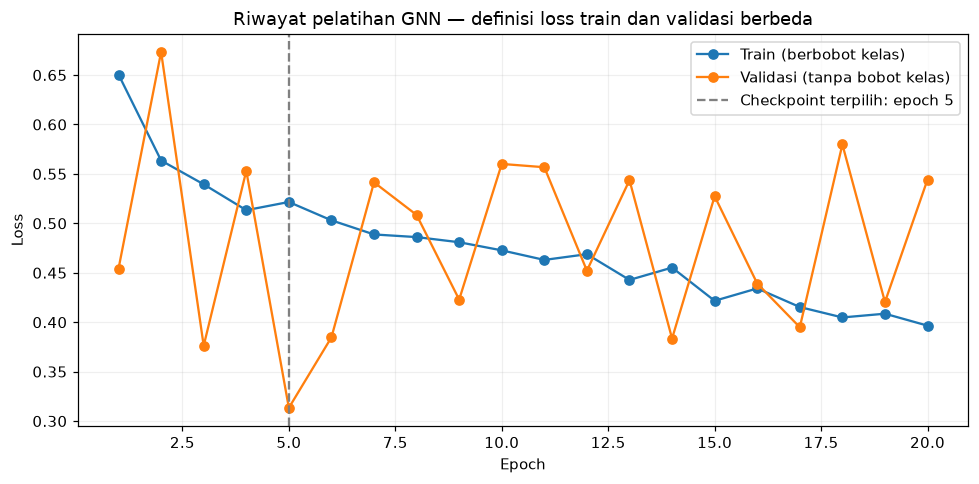

Checkpoint: epoch 5; jumlah epoch dijalankan: 20.


In [9]:
display(history)
best_epoch = int(gnn_info['best_epoch'])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history.epoch, history.train_loss, marker='o', label='Train (berbobot kelas)')
ax.plot(history.epoch, history.validation_loss, marker='o', label='Validasi (tanpa bobot kelas)')
ax.axvline(best_epoch, color='gray', ls='--', label=f'Checkpoint terpilih: epoch {best_epoch}')
ax.set(xlabel='Epoch', ylabel='Loss', title='Riwayat pelatihan GNN — definisi loss train dan validasi berbeda')
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
save_figure(fig, '05_riwayat_pelatihan')
print(f'Checkpoint: epoch {best_epoch}; jumlah epoch dijalankan: {gnn_info["epochs_run"]}.')

## 10. Melihat episode yang salah diprediksi

Berikut contoh FP dengan skor tertinggi dan FN dengan skor terendah agar kasus yang berlawanan dengan anotasi mudah ditemukan.
`candidate_id`, pertandingan, periode, dan waktu kehilangan bola dapat dipakai untuk membuka kembali visualisasi anotasi.
Skor tinggi/rendah menunjukkan keyakinan relatif model, **bukan bukti bahwa anotasi pengguna salah**.
Jika menemukan masalah label test, dokumentasikan revisi dan rancang evaluasi baru; jangan mengubah label hanya untuk menaikkan skor.

In [10]:
gnn_test = test_predictions[test_predictions.model.eq('temporal_gnn')].copy()
context_columns = ['candidate_id', 'period_id', 'loss_timestamp', 'annotation_confidence', 'annotation_notes']
errors = gnn_test[gnn_test.y_true.ne(gnn_test.y_pred)].merge(
    annotations[context_columns], on='candidate_id', how='left', validate='one_to_one'
)
errors['jenis_kesalahan'] = np.where(errors.y_true.eq(0), 'FP', 'FN')
example_columns = ['jenis_kesalahan', 'candidate_id', 'match_id', 'period_id', 'loss_timestamp',
                   'y_true', 'y_pred', 'probability', 'threshold', 'annotation_confidence', 'annotation_notes']
examples = pd.concat([
    errors[errors.jenis_kesalahan.eq('FP')].sort_values('probability', ascending=False).head(5),
    errors[errors.jenis_kesalahan.eq('FN')].sort_values('probability').head(5),
])
display(examples[example_columns].reset_index(drop=True))
print(f'Semua {len(errors)} kesalahan GNN diekspor sebagai CSV, bukan hanya contoh di atas.')

,jenis_kesalahan,candidate_id,match_id,period_id,loss_timestamp,y_true,y_pred,probability,threshold,annotation_confidence,annotation_notes
0,FP,J03WPY_P1_F37619,J03WPY,1,0 days 00:18:24.760000,0,1,0.935472,0.600231,2,NaN
1,FP,J03WPY_P1_F75152,J03WPY,1,0 days 00:43:26.080000,0,1,0.929970,0.600231,2,aku ragu karena posisi pemain seperti melakuka...
2,FP,J03WPY_P1_F38490,J03WPY,1,0 days 00:18:59.600000,0,1,0.927572,0.600231,2,NaN
3,FP,J03WPY_P2_F166841,J03WPY,2,0 days 00:44:33.640000,0,1,0.916535,0.600231,2,NaN
4,FP,J03WPY_P2_F172596,J03WPY,2,0 days 00:48:23.840000,0,1,0.891413,0.600231,2,NaN
5,FN,J03WPY_P1_F34461,J03WPY,1,0 days 00:16:18.440000,1,0,0.260403,0.600231,2,NaN
6,FN,J03WPY_P2_F175275,J03WPY,2,0 days 00:50:11,1,0,0.264675,0.600231,2,aku ragu ragu karena situasi nya seperti melak...
7,FN,J03WPY_P1_F11773,J03WPY,1,0 days 00:01:10.920000,1,0,0.331171,0.600231,2,NaN
8,FN,J03WPY_P2_F154926,J03WPY,2,0 days 00:36:37.040000,1,0,0.409531,0.600231,2,NaN
9,FN,J03WPY_P2_F154922,J03WPY,2,0 days 00:36:36.880000,1,0,0.416973,0.600231,2,NaN


Semua 43 kesalahan GNN diekspor sebagai CSV, bukan hanya contoh di atas.


## 11. Kualitas anotasi dan batas kesimpulan

Kelengkapan anotasi dan lolos pemeriksaan berkas tidak sama dengan kesepakatan antarpenilai.
Tampilkan status confidence dan asal anotator agar keterbatasan sumber label dapat ditinjau.
Confidence di sini adalah tingkat keyakinan **anotator**, berbeda dari probabilitas keluaran model.

In [11]:
quality = episodes.groupby(['split', 'annotation_confidence']).size().unstack(fill_value=0).reindex(SPLITS)
display(quality.rename_axis(columns='confidence_anotator'))
display(annotations.groupby('annotator', dropna=False).size().rename('episode').to_frame())
low_conf = episodes[episodes.annotation_confidence.eq(1)]
print(f'Label confidence 1 yang masuk manifest: {len(low_conf)}.')
if len(low_conf):
    display(low_conf[['candidate_id', 'split', 'gegenpressing_label', 'annotation_confidence']])
print(f'Baris dalam antrean review yang tersimpan saat run: {len(review_queue)}.')
limitations = [
    f'Test berisi {test_n} episode dari {test_match_n} pertandingan; belum evaluasi silang antarpertandingan.',
    'Episode dalam pertandingan dapat saling berkaitan; jangan menganggap semuanya sampel independen untuk uji statistik.',
    'Label positif dominan. Laporkan kelas negatif, macro F1, dan balanced accuracy bersama accuracy/F1 positif.',
    f'Ada {len(low_conf)} label confidence 1 dalam manifest; pemeriksaan berkas tidak menilai kebenaran taktis label.',
    'Belum ada pengukuran kesepakatan penilai independen dalam laporan ini.',
    'Perbedaan model bersifat deskriptif pada satu run/split; belum membuktikan keunggulan umum atau signifikansi statistik.',
    'Prediksi mendeteksi anotasi gegenpressing menggunakan jendela observasi; bukan deteksi seketika tepat saat kehilangan bola.',
    'Hasil ini belum mengukur efek kausal taktik, nilai VAEP, atau keberhasilan merebut bola kembali sebagai target klasifikasi.',
]
display(Markdown('\n'.join('- ' + item for item in limitations)))

confidence_anotator,1,2,3
split,,,
train,6,1312,37
validation,0,194,1
test,0,322,1


,episode
annotator,
codex_ai_review,3
rizal,1870


Label confidence 1 yang masuk manifest: 6.


,candidate_id,split,gegenpressing_label,annotation_confidence
327,J03WMX_P1_F12133,train,1,1
520,J03WMX_P1_F72996,train,1,1
525,J03WMX_P1_F73826,train,0,1
526,J03WMX_P1_F73879,train,0,1
590,J03WMX_P2_F119897,train,1,1
950,J03WOH_P2_F103255,train,0,1


Baris dalam antrean review yang tersimpan saat run: 6.


- Test berisi 323 episode dari 1 pertandingan; belum evaluasi silang antarpertandingan.
- Episode dalam pertandingan dapat saling berkaitan; jangan menganggap semuanya sampel independen untuk uji statistik.
- Label positif dominan. Laporkan kelas negatif, macro F1, dan balanced accuracy bersama accuracy/F1 positif.
- Ada 6 label confidence 1 dalam manifest; pemeriksaan berkas tidak menilai kebenaran taktis label.
- Belum ada pengukuran kesepakatan penilai independen dalam laporan ini.
- Perbedaan model bersifat deskriptif pada satu run/split; belum membuktikan keunggulan umum atau signifikansi statistik.
- Prediksi mendeteksi anotasi gegenpressing menggunakan jendela observasi; bukan deteksi seketika tepat saat kehilangan bola.
- Hasil ini belum mengukur efek kausal taktik, nilai VAEP, atau keberhasilan merebut bola kembali sebagai target klasifikasi.

## 12. Ringkasan hasil yang bisa dijadikan bahan penulisan

Paragraf berikut dibentuk otomatis dari tabel, bukan angka contoh. Gunakan sebagai bahan **Hasil dan Pembahasan**,
lalu sesuaikan istilah dan format artikel dengan arahan dosen. Kesimpulan hanya berlaku pada evaluasi yang dijalankan.

Untuk menjawab *efektivitas gegenpressing*, masih diperlukan analisis outcome yang terpisah
(misalnya hubungan gegenpressing dengan perebutan kembali bola), batasan data, dan definisi operasional efektivitas.
Keakuratan mendeteksi sebuah taktik tidak sama dengan efektivitas taktik tersebut.

In [12]:
train_n = int(split_table.loc['train', 'episode'])
val_n = int(split_table.loc['validation', 'episode'])
summary = (
    f'Penelitian menggunakan {len(episodes):,} episode beranotasi, dengan {train_n:,} episode latih, '
    f'{val_n} episode validasi, dan {test_n} episode uji. Pembagian dilakukan berdasarkan pertandingan. '
    f'Pada data uji dari {test_match_n} pertandingan, Temporal GNN memperoleh accuracy {gnn.accuracy:.2%}, '
    f'precision kelas positif {gnn.precision_1:.2%}, recall kelas positif {gnn.recall_1:.2%}, '
    f'dan F1 kelas positif {gnn.f1_1:.2%}. XGBoost memperoleh accuracy {xgb.accuracy:.2%} '
    f'dan F1 kelas positif {xgb.f1_1:.2%}. Selisih accuracy GNN terhadap XGBoost adalah '
    f'{100 * (gnn.accuracy - xgb.accuracy):.2f} poin persentase. '
    f'GNN memiliki macro F1 {gnn.macro_f1:.2%}, balanced accuracy {gnn.balanced_accuracy:.2%}, '
    f'ROC-AUC {gnn.roc_auc:.4f}, dan AP {gnn.ap:.4f}. '
    f'Recall kelas bukan gegenpressing sebesar {gnn.recall_0:.2%} menunjukkan keterbatasan '
    f'pengenalan kelas negatif. Terdapat {int(gnn.fp)} false positive dan {int(gnn.fn)} false negative. '
    'Hasil mendukung kinerja deteksi GNN yang lebih tinggi pada split ini, namun belum membuktikan '
    'generalisasi lintas pertandingan yang luas, signifikansi perbedaan, atau efektivitas kausal gegenpressing.'
)
display(Markdown(summary))

Penelitian menggunakan 1,873 episode beranotasi, dengan 1,355 episode latih, 195 episode validasi, dan 323 episode uji. Pembagian dilakukan berdasarkan pertandingan. Pada data uji dari 1 pertandingan, Temporal GNN memperoleh accuracy 86.69%, precision kelas positif 89.01%, recall kelas positif 94.92%, dan F1 kelas positif 91.87%. XGBoost memperoleh accuracy 80.80% dan F1 kelas positif 88.60%. Selisih accuracy GNN terhadap XGBoost adalah 5.88 poin persentase. GNN memiliki macro F1 77.56%, balanced accuracy 75.07%, ROC-AUC 0.8764, dan AP 0.9533. Recall kelas bukan gegenpressing sebesar 55.22% menunjukkan keterbatasan pengenalan kelas negatif. Terdapat 30 false positive dan 13 false negative. Hasil mendukung kinerja deteksi GNN yang lebih tinggi pada split ini, namun belum membuktikan generalisasi lintas pertandingan yang luas, signifikansi perbedaan, atau efektivitas kausal gegenpressing.

## 13. Menyimpan tabel, gambar, dan catatan sumber

Keluaran tersimpan dalam `artifacts/laporan_hasil/<nama_run>/`:
tabel pembagian data, metrik semua split, metrik uji, metrik per kelas, kesalahan GNN, gambar PNG,
ringkasan Markdown, dan metadata sumber. CSV metrik memakai skala 0–1 kecuali tabel dengan akhiran `persen`.
Menjalankan ulang notebook akan memperbarui laporan untuk run terpilih; model dan anotasi asli tetap menjadi sumber baca.

In [13]:
split_table.to_csv(REPORT_DIR / 'pembagian_data.csv', index_label='split')
recalculated.to_csv(REPORT_DIR / 'metrik_semua_split.csv', index=False)
test_metrics.to_csv(REPORT_DIR / 'metrik_uji.csv', index_label='model')
percent_table.to_csv(REPORT_DIR / 'metrik_uji_persen.csv', index_label='model')
class_metrics.to_csv(REPORT_DIR / 'metrik_per_kelas.csv', index=False)
errors[example_columns].to_csv(REPORT_DIR / 'kesalahan_gnn_uji.csv', index=False)
check_table.to_csv(REPORT_DIR / 'pemeriksaan_sumber.csv', index=False)
report_text = (
    '# Laporan hasil VAEP-Track\n\n'
    f'Sumber: `{RUN_DIR.name}`. Status: `{run_info["status"]}`. Seed: {SEED}.\n\n'
    + summary + '\n\n## Batas interpretasi\n\n'
    + '\n'.join('- ' + item for item in limitations)
    + '\n\n## Tabel uji (%)\n\n```text\n' + percent_table.round(2).to_string()
    + '\n```\n\nAP dihitung dengan average_precision_score; F1 kelas 1 bukan accuracy.\n'
)
(REPORT_DIR / 'ringkasan_hasil.md').write_text(report_text, encoding='utf-8')
report_metadata = {
    'source_run': RUN_DIR.name, 'source_status': run_info['status'],
    'seed': SEED, 'test_episodes': test_n, 'test_matches': test_match_n,
    'source_annotation_sha256': run_info.get('annotation_sha256'),
    'checks': {key: bool(value) for key, value in checks.items()},
    'checked_source_hashes': hash_rows,
    'metrics_recomputed_match_saved': True,
    'report_environment': {'python': platform.python_version(), **{
        package: importlib.metadata.version(package)
        for package in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'nbformat', 'nbclient']
    }},
    'training_environment': training_environment,
    'ap_definition': 'sklearn.metrics.average_precision_score',
    'test_threshold_optimization': False,
}
(REPORT_DIR / 'sumber_laporan.json').write_text(json.dumps(report_metadata, indent=2), encoding='utf-8')
print('SELESAI. Keluaran laporan:')
display(pd.DataFrame({'berkas': sorted(p.name for p in REPORT_DIR.iterdir() if p.is_file())}))

SELESAI. Keluaran laporan:


,berkas
0,01_distribusi_data.png
1,02_perbandingan_metrik_uji.png
2,03_confusion_matrix.png
3,04_roc_precision_recall.png
4,05_riwayat_pelatihan.png
5,kesalahan_gnn_uji.csv
6,metrik_per_kelas.csv
7,metrik_semua_split.csv
8,metrik_uji.csv
9,metrik_uji_persen.csv
